In [1]:
pip install --upgrade --quiet google-cloud-aiplatform[agent_engines,adk]>=1.112

In [4]:
from google.colab import auth
PROJECT_ID = "qwiklabs-gcp-00-d3822d6ac0fc"
MODEL_LOCATION = "global"
LOCATION = 'us-central1'
auth.authenticate_user(project_id=PROJECT_ID)

In [12]:
from google.adk.agents import Agent
from vertexai import agent_engines
from google.adk.tools import google_search
from vertexai.preview.reasoning_engines import AdkApp
from vertexai import agent_engines


import os

In [5]:
os.environ["GOOGLE_GENAI_USE_VERTEXAI"] = "TRUE"
os.environ["GOOGLE_CLOUD_PROJECT"] = PROJECT_ID
os.environ["GOOGLE_CLOUD_LOCATION"] = LOCATION

client = vertexai.Client(
    project=PROJECT_ID,               # Your project ID.
    location=LOCATION,                # Your cloud region.
)

In [6]:


vertexai.init(
    project=PROJECT_ID,
    location=LOCATION,
    staging_bucket= 'gs://stagingbucketforchallenege2222'
)

In [10]:

search_agent = Agent(
 name="Google",
 model="gemini-3.6-flash",
 description=(
 "You can search Google…"
 ),
 instruction=(
 """You are a helpful Chatbot."""
 ),
 tools=[google_search]
)

In [13]:

app = AdkApp(agent=search_agent,
             env_vars={'GOOGLE_CLOUD_LOCATION':MODEL_LOCATION})


In [14]:
remote_agent = agent_engines.create(
 app,
 requirements=["google-cloud-aiplatform[agent_engines,adk]"],
)


INFO:vertexai.agent_engines:Identified the following requirements: {'cloudpickle': '3.1.2', 'google-cloud-aiplatform': '2.5.0', 'pydantic': '2.13.4'}
INFO:vertexai.agent_engines:The following requirements are appended: {'cloudpickle==3.1.2', 'pydantic==2.13.4'}
INFO:vertexai.agent_engines:The final list of requirements: ['google-cloud-aiplatform[agent_engines,adk]', 'cloudpickle==3.1.2', 'pydantic==2.13.4']
INFO:vertexai.agent_engines:Using bucket stagingbucketforchallenege2222
INFO:vertexai.agent_engines:Wrote to gs://stagingbucketforchallenege2222/agent_engine/agent_engine.pkl
INFO:vertexai.agent_engines:Writing to gs://stagingbucketforchallenege2222/agent_engine/requirements.txt
INFO:vertexai.agent_engines:Creating in-memory tarfile of extra_packages
INFO:vertexai.agent_engines:Writing to gs://stagingbucketforchallenege2222/agent_engine/dependencies.tar.gz
INFO:vertexai.agent_engines:Creating AgentEngine
INFO:vertexai.agent_engines:Create AgentEngine backing LRO: projects/7552047062

In [ ]:
from vertexai import agent_engines

remote_agent = agent_engines.get(
    "projects/755204706277/locations/us-central1/reasoningEngines/3906899339900878848"
)

print(remote_agent)

Falling back to grpc since no async rest credentials were detected.


resource name: projects/755204706277/locations/us-central1/reasoningEngines/3906899339900878848


In [15]:
async for event in remote_agent.async_stream_query(
    user_id="test_user",
    message="Hello! What can you do?"
):
    print(event)

{'model_version': 'gemini-3.6-flash', 'content': {'parts': [{'text': "Hello! I'm an AI assistant, and I'm here to help you with a wide variety of tasks. Here are some of the main things I can do:\n\n* **Answer Questions & Provide Information:** Explain complex topics, offer facts, summarize information, or teach you something new.\n* **Search the Web:** Find up-to-date information, news, current events, research, and data from around the web.\n* **Writing & Creativity:** Help draft emails, essays, stories, or poems, as well as edit, proofread, and brainstorm ideas.\n* **Coding & Math:** Write, debug, and explain code in various programming languages, or help solve mathematical and logical problems.\n* **Planning & Organization:** Help create schedules, study plans, travel itineraries, recipes, and to-do lists.\n\nHow can I help you today?", 'thought_signature': 'AY89a19O-5wH-o6IeE51bOUQg1C0BNRtMfIapKxxZ-xEinihlml-LFwkFpdnuMgBvFy4GgyNl36yYxOgo9CDyrrUnaPHWdJTFirxe_8O3oRVNN9CJB9Res8AZcynU

In [17]:
async for event in remote_agent.async_stream_query(
    user_id="test_user",
    message="What could the eagles do this week to actually get a win?"
):
    if event.get("content"):
        for part in event["content"].get("parts", []):
            if part.get("text"):
                print(part["text"])

Heading into **Week 6 against the Carolina Panthers at Lincoln Financial Field**, the Philadelphia Eagles find themselves sitting at 2-3 after dropping three straight games (including back-to-back late losses against the Rams and Jaguars in London). 

To snap their losing streak and get back in the win column this week, the Eagles need to address several key tactical and personnel challenges:

---

### 1. **Solve the Running Back Depth Crisis**
* **The Issue:** The Eagles are severely depleted in the backfield. Saquon Barkley has been sidelined with a hamstring injury, Tank Bigsby has been banged up, and rookie Will Shipley suffered a partial plantar fascia tear in London. 
* **The Fix:** With the backfield thinned out, offensive coordinator Sean Mannion needs to adapt. Look for the Eagles to rely heavily on quick, short-passing schemes (screen passes, flat routes to tight ends and slot receivers) to serve as an extension of the run game. Utilizing Jalen Hurts' designed quarterback run

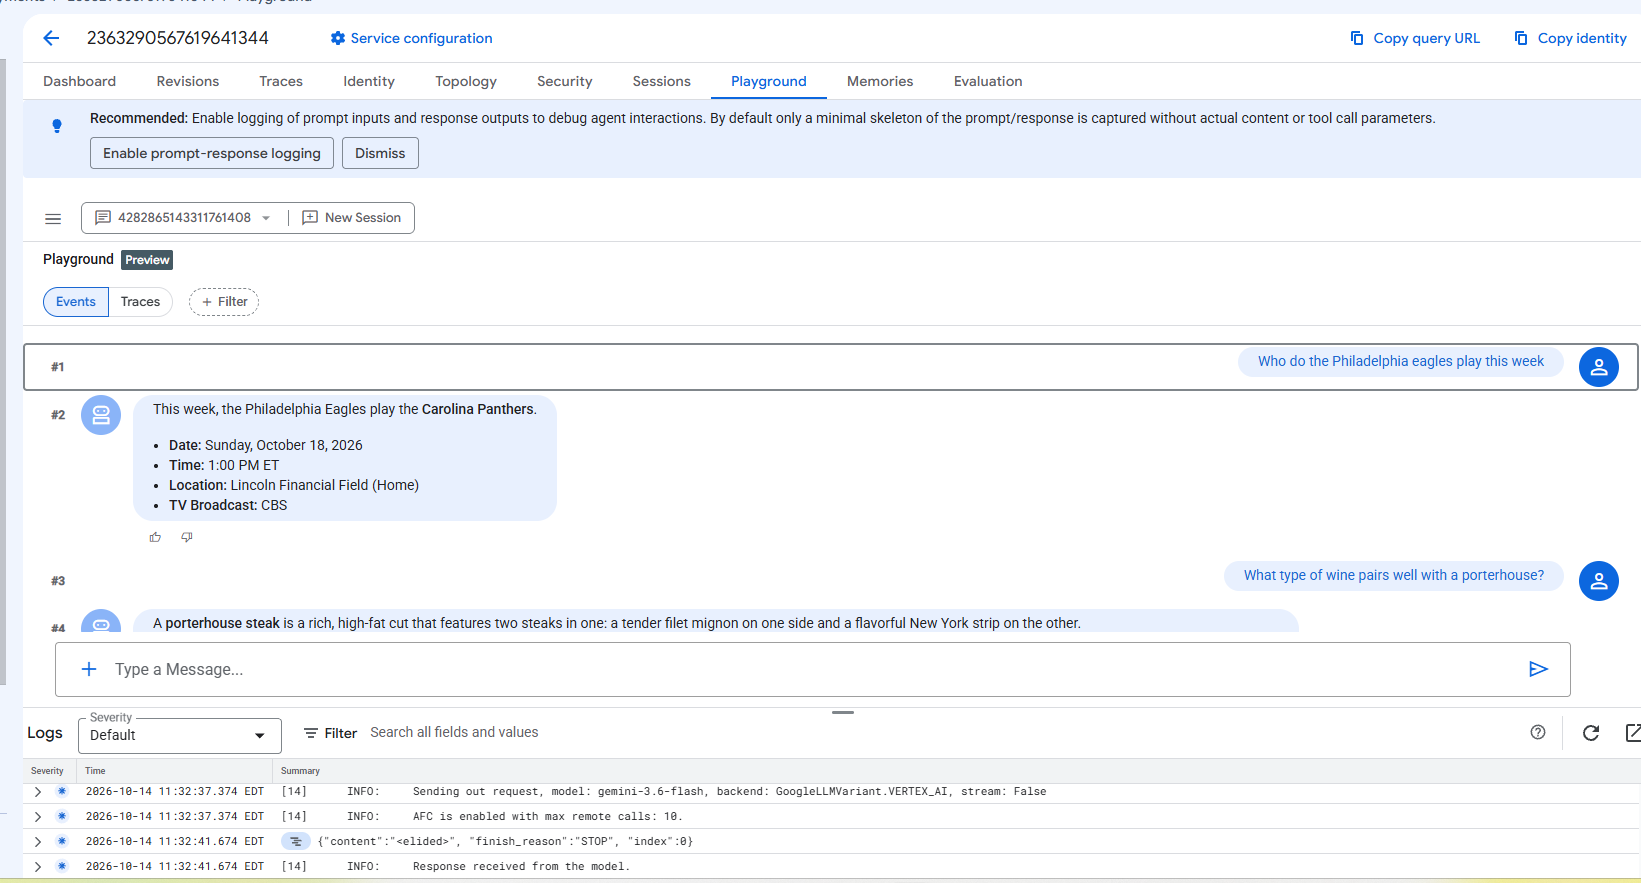